# Level 1 — Training majority

Daily next-fixing USD/IDR UP/DOWN on the combined corpus. See [the protocol](../PROTOCOL.md) for selection and test scope.

In [1]:
from pathlib import Path
import os
import sys
import json

for key in ["OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[key] = "1"
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import torch
from threadpoolctl import threadpool_limits
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/final/metadata.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.task_3.training.experiment import Experiment, prepare_run, freeze_final, final_report, read_json, OUTPUT, FIGURES

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
threadpool_limits(limits=1)
pd.options.display.float_format = "{:.4f}".format
from src.task_3.training.all_tests import prepare as prepare_all_tests, TEST_FIGURES
prepare_all_tests()
prepare_run()
experiment = Experiment(1, "L1-a")


## Data

Use the fixed CSV folds; purge boundaries by target availability.

In [2]:
rows = []
for fold in [1, 2, 3]:
    train, val, _, _ = experiment.frames(fold)
    for role, frame in [("train", train), ("validation", val)]:
        rows.append({"fold": fold, "role": role, "n": len(frame), "first": frame.Date.min().date(), "last": frame.Date.max().date(), "up": int(frame.y.sum()), "news": int(frame.n_berita.sum())})
display(pd.DataFrame(rows))
print("Representation:", experiment.rep)
print("Configuration:", experiment.config)


Representation: R3
Configuration: None


,fold,role,n,first,last,up,news
0,1,train,453,2021-09-29,2023-08-15,260,6759
1,1,validation,158,2023-08-21,2024-04-19,94,2105
2,2,train,612,2021-09-29,2024-04-19,355,8886
3,2,validation,159,2024-04-23,2024-12-12,81,1960
4,3,train,772,2021-09-29,2024-12-12,437,10865
5,3,validation,158,2024-12-16,2025-08-26,79,1945


## Training

Select checkpoints by five-epoch mean validation log loss. Report individual-seed averages; logistic regression is a benchmark for fixed concat inputs.

In [3]:
summary = experiment.train()
display(summary)
for filename in ["logistic_comparison.csv", "diagnostics.csv"]:
    path = experiment.directory / filename
    if path.exists():
        display(pd.read_csv(path))


,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
statistic,,,,,,,,
mean,0.0000,0.3479,0.5000,0.5348,0.5000,0.2502,0.6937,0.0526
std,0.0000,0.0218,0.0000,0.0523,0.0000,0.0076,0.0154,0.0274


,fold


## Validation

Confusion counts average seeds. Curves show seed42 with the training-prior reference.

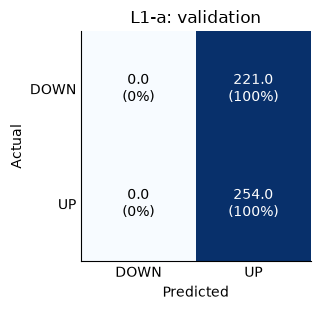

In [4]:
figures = experiment.plot()
plt.show()
for figure in figures:
    plt.close(figure)


## Saved results

Model files include training-fitted preprocessing; article encoders are shared separately.

In [5]:
display(experiment.finalize_level())
metadata = read_json(experiment.directory / "run_metadata.json")
print("Saved:", experiment.directory.relative_to(ROOT))
print("Evaluation rows:", metadata["evaluation_rows"])


Saved: src/task_3/output/model/improved_v1/level_1/01_training_majority
Evaluation rows: 475


,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
model_id,,,,,,,,
L1-a,0.0000,0.3479,0.5000,0.5348,0.5000,0.2502,0.6937,0.0526
L1-b,0.0616,0.5308,0.5307,0.5368,0.5308,0.4621,15.9279,0.4632
L1-c,0.0488,0.4800,0.5191,0.5417,0.5527,0.2517,0.6989,0.0900
L1-d,0.0089,0.3495,0.5007,0.5355,0.5007,0.2489,0.6909,0.0376
L1-e,0.0524,0.4696,0.5187,0.5425,0.5388,0.2531,0.7018,0.0856


## Final test

Refit this condition using its validation-selected configuration and median epochs. Test comparisons are exploratory; settings remain fixed.

L1-a seed-1: reused verified 0-epoch model
Completed test L1-a: MCC0.0000, AUC0.5000
Out[6]: 
   level model_id    mcc  macro_f1  ...  roc_auc  brier  log_loss  ece_10
0      1     L1-a 0.0000    0.3683  ...   0.5000 0.2439    0.6809  0.0281

[1 rows x 10 columns]


,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
statistic,,,,,,,,
mean,0.0000,0.3683,0.5000,0.5830,0.5000,0.2439,0.6809,0.0281
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


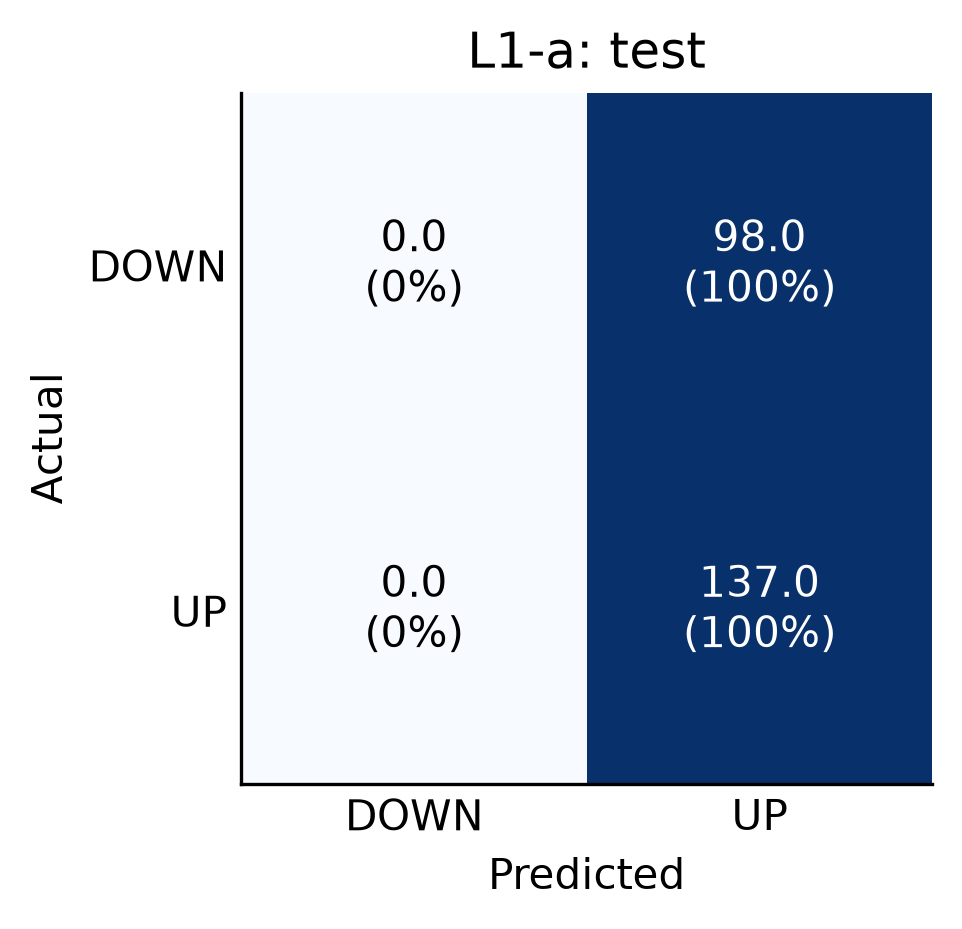

In [6]:
display(experiment.final_test())
display(Image(filename=str(TEST_FIGURES / experiment.model_id / "confusion_matrix.png")))
final_report()
